## 1. Imports

In [51]:
import json
import re
import csv
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from math import log, sqrt

import numpy as np
from nltk.stem import PorterStemmer
from spacy.lang.en.stop_words import STOP_WORDS

# seed for reproducibility
SEED = 42
np.random.seed(SEED)

## 2. Data Loading

In [2]:
# define data directory and check for required files
DATA_DIR = Path("../../data").resolve()
dev_file = DATA_DIR / "dev_labeled_ChatGPT.jsonl"
passages_file = DATA_DIR / "passages_bm25_ChatGPT_humfacts.jsonl"

In [3]:
def read_jsonl(file_path):
    """Read a JSON Lines file into a list of dictionaries."""
    records = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON in {file_path}, line {line_number}"
                ) from exc

    return records

In [23]:
# Load the development and passage data
dev_data = read_jsonl(dev_file)
passages_data = read_jsonl(passages_file)

# Display information about the loaded data
print(f"Loaded {len(dev_data)} development records.")
print(f"Loaded {len(passages_data)} passage records.")

Loaded 31 development records.
Loaded 5427 passage records.


In [5]:
# Display keys and example records
print("Development record keys:")
if dev_data:
    print(list(dev_data[0].keys()))

print("\nPassage record keys:")
if passages_data:
    print(list(passages_data[0].keys()))

# Dsplay example records
if dev_data:
    print("\nExample development record:")
    print(json.dumps(dev_data[0], indent=2, ensure_ascii=False)[:2500])

# Display example passage record
if passages_data:
    print("\nExample passage record:")
    print(json.dumps(passages_data[0], indent=2, ensure_ascii=False)[:2500])

Development record keys:
['input', 'output', 'topic', 'cat', 'annotations']

Passage record keys:
['name', 'sent', 'passages']

Example development record:
{
  "input": "Question: Tell me a bio of Marianne McAndrew.",
  "output": "Marianne McAndrew is an American actress and singer, born on November 21, 1942, in Cleveland, Ohio. She began her acting career in the late 1960s, appearing in various television shows and films. Her notable film appearances include the role of Irene Molloy in the 1969 film adaptation of the musical \"Hello, Dolly!\", and as Princess Zareta in the 1976 film \"The Blue Bird\". She also had recurring roles on popular television shows such as \"The Love Boat\" and \"Fantasy Island\". In addition to her acting career, McAndrew was a trained singer and performed in various stage productions, including the Broadway production of \"The King and I\". She retired from acting in the 1990s and currently resides in California.",
  "topic": "Marianne McAndrew",
  "cat": [

## 3. Label Mapping and Example Construction

In [6]:
# Binary mapping used in the earlier results:
# S = supported
# NS = not supported
# IR = irrelevant (treated as unsupported for this experiment)

RAW_LABEL_MAP = {
    "S": 1,
    "NS": 0,
    "IR": 0,
}

fact_to_passage = {}

for record in passages_data:
    fact_text = record.get("sent")
    passages = record.get("passages") or []

    if isinstance(fact_text, str):
        fact_to_passage[fact_text] = passages

In [7]:
# store the processed examples in a list
examples = []

missing_passage_facts = 0
missing_label_facts = 0
unrecognized_label_facts = 0
observed_labels = Counter()

for record in dev_data:
    annotations = record.get("annotations") or []

    if isinstance(annotations, dict):
        annotations = [annotations]

    for sentence_annotation in annotations:
        atomic_facts = (
            sentence_annotation.get("human-atomic-facts") or []
        )

        for fact in atomic_facts:
            fact_text = fact.get("text")
            raw_label = fact.get("label")

            if not fact_text or raw_label is None:
                missing_label_facts += 1
                continue

            label = str(raw_label).strip().upper()
            observed_labels[label] += 1

            if label not in RAW_LABEL_MAP:
                unrecognized_label_facts += 1
                continue

            if fact_text not in fact_to_passage:
                missing_passage_facts += 1
                continue

            passages = fact_to_passage[fact_text] or []

            examples.append({
                "fact": fact_text,
                "passages": passages,
                "label": label,
                "gold_binary": RAW_LABEL_MAP[label],
            })

In [8]:
print("Labels found:", sorted(observed_labels.keys()))
print("Label counts:", dict(observed_labels))
print(f"Usable examples: {len(examples)}")
print(f"Missing passage matches: {missing_passage_facts}")
print(f"Missing text/label records: {missing_label_facts}")
print(f"Unrecognized labels skipped: {unrecognized_label_facts}")

if not examples:
    raise ValueError(
        "No usable examples were constructed. Inspect the JSONL schemas "
        "and confirm that fact text matches the passage records."
    )

Labels found: ['IR', 'NS', 'S']
Label counts: {'NS': 93, 'S': 112, 'IR': 16}
Usable examples: 221
Missing passage matches: 0
Missing text/label records: 0
Unrecognized labels skipped: 0


## 4. Preprocessing: Stopwords and Stemming

In [9]:
stemmer = PorterStemmer()

STOPWORDS = set("""
a an the and or but if then else when while
is am are was were be been being
to of in on at by for from with as
it its this that these those
he she they them their we our you your
i me my
""".split())

In [ ]:
stemmer = PorterStemmer()

# Keep negation words: removing them makes a fact and contradicting evidence look more similar.
NEGATION_WORDS = {"no", "not", "nor", "never", "none", "n't"}
STOPWORDS = set(STOP_WORDS) - NEGATION_WORDS

## 5. Tokenization, N-grams and Sentence Splitting

In [ ]:
def tokenize(
    text,
    lower=True,
    remove_stop=True,
    stem=True,
):
    """Clean and tokenize text with configurable preprocessing."""

    if not isinstance(text, str):
        text = ""

    if lower:
        text = text.lower()

    # Remove HTML-like tags.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove punctuation while preserving letters, digits and whitespace.
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    tokens = text.split()

    if remove_stop:
        tokens = [
            token for token in tokens
            if token not in STOPWORDS
        ]

    if stem:
        tokens = [
            stemmer.stem(token)
            for token in tokens
        ]

    return tokens


def make_ngrams(tokens, ngram_range=(1, 2)):
    """Generate word n-grams within the requested inclusive range."""

    min_n, max_n = ngram_range
    features = []

    for n in range(min_n, max_n + 1):
        for start in range(len(tokens) - n + 1):
            features.append(
                "_".join(tokens[start:start + n])
            )

    return features


def get_passage_text(passage):
    """Support passage records stored as dictionaries or strings."""

    if isinstance(passage, str):
        return passage

    if isinstance(passage, dict):
        return str(passage.get("text", "") or "")

    return ""


def split_into_sentences(text):
    """Split passage text using punctuation followed by whitespace."""

    if not isinstance(text, str) or not text.strip():
        return []

    text = re.sub(r"<[^>]+>", " ", text)
    parts = re.split(r"(?<=[.!?])\s+", text.strip())

    return [
        part.strip()
        for part in parts
        if part.strip()
    ]


In [20]:
print("Example tokens:", tokenize("The cats were running quickly."))
print("Example unigrams and bigrams:",
      make_ngrams(["solar", "panel", "fault"], (1, 2)))

Example tokens: ['cat', 'run', 'quickli']
Example unigrams and bigrams: ['solar', 'panel', 'fault', 'solar_panel', 'panel_fault']


## 6. TF-IDF Vectors and Cosine Similarity

In [28]:
def term_frequency(features):
    """Count occurrences of each token or n-gram."""
    return Counter(features)

In [ ]:
def build_tfidf_vectors(feature_documents):
    """Build normalized TF-IDF vectors using only Python dictionaries."""

    counters = [
        term_frequency(document)
        for document in feature_documents
    ]

    document_frequency = Counter()

    for counts in counters:
        document_frequency.update(counts.keys())

    n_documents = len(counters)

    if n_documents == 0:
        return []

    idf = {
        term: log(
            (n_documents + 1) /
            (frequency + 1)
        ) + 1.0
        for term, frequency in document_frequency.items()
    }

    normalized_vectors = []

    for counts in counters:
        vector = {}

        for term, count in counts.items():
            # Log-scaled term frequency.
            tf = 1.0 + log(count)
            vector[term] = tf * idf[term]

        # L2 normalization.
        norm = sqrt(
            sum(weight * weight for weight in vector.values())
        )

        if norm > 0:
            vector = {
                term: weight / norm
                for term, weight in vector.items()
            }

        normalized_vectors.append(vector)

    return normalized_vectors

In [30]:
def cosine_similarity_sparse(vector_a, vector_b):
    """Cosine similarity for sparse dictionaries."""

    if not vector_a or not vector_b:
        return 0.0

    # Vectors are already L2-normalized.
    # Iterate through the smaller dictionary.
    if len(vector_a) > len(vector_b):
        vector_a, vector_b = vector_b, vector_a

    return float(
        sum(
            value * vector_b.get(term, 0.0)
            for term, value in vector_a.items()
        )
    )


In [ ]:
def tfidf_score(
    fact,
    passages,
    sentence_level=True,
    ngram_range=(1, 2),
    lower=True,
    remove_stop=True,
    stem=True,
):
    """
    Score how strongly the fact overlaps with its evidence.

    Returns the maximum TF-IDF cosine similarity in [0, 1].
    """

    fact_tokens = tokenize(
        fact,
        lower=lower,
        remove_stop=remove_stop,
        stem=stem,
    )

    fact_features = make_ngrams(
        fact_tokens,
        ngram_range=ngram_range,
    )

    if not fact_features:
        return 0.0

    evidence_units = []

    for passage in passages or []:
        passage_text = get_passage_text(passage)

        if not passage_text.strip():
            continue

        if sentence_level:
            units = split_into_sentences(passage_text)
        else:
            units = [passage_text]

        evidence_units.extend(units)

    candidate_feature_documents = []

    for unit in evidence_units:
        tokens = tokenize(
            unit,
            lower=lower,
            remove_stop=remove_stop,
            stem=stem,
        )

        features = make_ngrams(
            tokens,
            ngram_range=ngram_range,
        )

        if features:
            candidate_feature_documents.append(features)

    if not candidate_feature_documents:
        return 0.0

    # The fact is the query document; remaining documents are evidence units.
    all_documents = [
        fact_features
    ] + candidate_feature_documents

    vectors = build_tfidf_vectors(all_documents)

    query_vector = vectors[0]
    evidence_vectors = vectors[1:]

    if not query_vector:
        return 0.0

    similarities = [
        cosine_similarity_sparse(query_vector, evidence_vector)
        for evidence_vector in evidence_vectors
    ]

    if not similarities:
        return 0.0

    return float(max(similarities))

## 7. IDF-weighted Recall

In [32]:
def compute_idf(token_documents):
    """Smoothed IDF over the fact + its evidence units (same formula as build_tfidf_vectors)."""
    document_frequency = Counter()
    for tokens in token_documents:
        document_frequency.update(set(tokens))
    n_documents = len(token_documents)
    return {
        term: log((n_documents + 1) / (frequency + 1)) + 1.0
        for term, frequency in document_frequency.items()
    }


In [34]:
def idf_recall_score(
    fact,
    passages,
    sentence_level=False,
    lower=True,
    remove_stop=True,
    stem=True,
):
    """
    IDF-weighted recall of the fact's terms.

    score = sum(idf of fact terms found in the evidence unit) / sum(idf of all fact terms)

    Unlike cosine, this is asymmetric: it asks "how much of the FACT is covered
    by the evidence?" and is not penalised when the evidence unit is long.
    Returns the maximum over evidence units, in [0, 1].
    """
    fact_terms = set(tokenize(fact, lower=lower, remove_stop=remove_stop, stem=stem))
    if not fact_terms:
        return 0.0

    evidence_units = []
    for passage in passages or []:
        passage_text = get_passage_text(passage)
        if not passage_text.strip():
            continue
        if sentence_level:
            evidence_units.extend(split_into_sentences(passage_text))
        else:
            evidence_units.append(passage_text)

    evidence_token_sets = []
    for unit in evidence_units:
        tokens = tokenize(unit, lower=lower, remove_stop=remove_stop, stem=stem)
        if tokens:
            evidence_token_sets.append(set(tokens))

    if not evidence_token_sets:
        return 0.0

    idf = compute_idf([list(fact_terms)] + [list(s) for s in evidence_token_sets])
    total_weight = sum(idf[term] for term in fact_terms)

    return float(max(
        sum(idf[term] for term in fact_terms & unit_terms) / total_weight
        for unit_terms in evidence_token_sets
    ))


## 8. Evaluation Metrics and Threshold Search

In [35]:

def compute_metrics(y_true, scores, threshold):
    """Calculate binary classification metrics without scikit-learn."""

    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    y_pred = (scores >= threshold).astype(int)

    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    total = len(y_true)
    accuracy = (tp + tn) / total if total else 0.0

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    f1 = (
        2.0 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    }


In [37]:
def find_best_threshold(y_true, scores):
    """Search thresholds from 0.000 to 1.000 in steps of 0.001."""

    threshold_grid = np.linspace(0.0, 1.0, 1001)

    results = [
        compute_metrics(y_true, scores, threshold)
        for threshold in threshold_grid
    ]

    # Accuracy is the main objective; F1 breaks ties.
    best = max(
        results,
        key=lambda result: (
            result["accuracy"],
            result["f1"],
        ),
    )

    return best, results


def score_examples(examples, config):
    """Score all examples using one configuration."""

    metric = config.get("metric", "cosine")
    scores = []

    for index, example in enumerate(examples, start=1):
        if metric == "idf_recall":
            score = idf_recall_score(
                fact=example["fact"],
                passages=example["passages"],
                sentence_level=config["sentence_level"],
                lower=config["lower"],
                remove_stop=config["remove_stop"],
                stem=config["stem"],
            )
        else:
            score = tfidf_score(
                fact=example["fact"],
                passages=example["passages"],
                sentence_level=config["sentence_level"],
                ngram_range=config["ngram_range"],
                lower=config["lower"],
                remove_stop=config["remove_stop"],
                stem=config["stem"],
            )

        scores.append(score)

        if index % 100 == 0:
            print(f"Scored {index}/{len(examples)} examples.")

    return np.asarray(scores, dtype=float)

## 9. Baseline Results

In [38]:
y_true = np.asarray(
    [example["gold_binary"] for example in examples],
    dtype=int,
)

baseline_config = {
    "ngram_range": (1, 2),
    "sentence_level": True,
    "lower": True,
    "remove_stop": True,
    "stem": True,
}

baseline_scores = score_examples(
    examples,
    baseline_config,
)

baseline_best, baseline_threshold_results = find_best_threshold(
    y_true,
    baseline_scores,
)

baseline_threshold = baseline_best["threshold"]

baseline_predictions = (
    baseline_scores >= baseline_threshold
).astype(int)

Scored 100/221 examples.
Scored 200/221 examples.


In [40]:
print(f"Examples:   {len(examples)}")
print(f"Score min:  {baseline_scores.min():.4f}")
print(f"Score max:  {baseline_scores.max():.4f}")
print(f"Score mean: {baseline_scores.mean():.4f}")
print(f"Score std:  {baseline_scores.std():.4f}")
print(f"Threshold:  {baseline_threshold:.3f}")
print(f"Accuracy:   {baseline_best['accuracy']:.4f}")
print(f"Precision:  {baseline_best['precision']:.4f}")
print(f"Recall:     {baseline_best['recall']:.4f}")
print(f"F1-score:   {baseline_best['f1']:.4f}")

print("\nConfusion matrix")
print("                 Predicted NS   Predicted S")
print(
    f"Actual NS         {baseline_best['TN']:>6}       "
    f"{baseline_best['FP']:>6}"
)
print(
    f"Actual S          {baseline_best['FN']:>6}       "
    f"{baseline_best['TP']:>6}"
)

Examples:   221
Score min:  0.0000
Score max:  0.7229
Score mean: 0.2114
Score std:  0.1462
Threshold:  0.125
Accuracy:   0.7195
Precision:  0.6689
Recall:     0.8839
F1-score:   0.7615

Confusion matrix
                 Predicted NS   Predicted S
Actual NS             60           49
Actual S              13           99


## 10. Threshold Sensitivity

In [41]:
print(
    f"{'Threshold':>10} "
    f"{'Accuracy':>10} "
    f"{'Precision':>10} "
    f"{'Recall':>10} "
    f"{'F1':>10}"
)

threshold_sensitivity = []

for step in range(11):
    threshold = round(baseline_threshold - 0.05 + step * 0.01, 3)

    metrics = compute_metrics(
        y_true,
        baseline_scores,
        threshold,
    )

    threshold_sensitivity.append(metrics)

    print(
        f"{threshold:>10.3f} "
        f"{metrics['accuracy']:>10.3f} "
        f"{metrics['precision']:>10.3f} "
        f"{metrics['recall']:>10.3f} "
        f"{metrics['f1']:>10.3f}"
    )

 Threshold   Accuracy  Precision     Recall         F1
     0.075      0.638      0.587      0.964      0.730
     0.085      0.661      0.606      0.946      0.739
     0.095      0.679      0.626      0.911      0.742
     0.105      0.692      0.637      0.911      0.750
     0.115      0.692      0.643      0.884      0.744
     0.125      0.719      0.669      0.884      0.762
     0.135      0.710      0.669      0.848      0.748
     0.145      0.710      0.671      0.839      0.746
     0.155      0.701      0.674      0.795      0.730
     0.165      0.706      0.688      0.768      0.726
     0.175      0.701      0.692      0.741      0.716


## 11. Ablation Study

In [ ]:
# changes one design choice at a time, 
# re-runs the whole pipeline, and measures how much that choice matters.
# stemming on or off
# stopword removal on or off
# unigrams vs unigrams + bigrams
# sentence level vs passage level
# cosine vs IDF-recall
ablation_configs = [
    {
        "name": "Unigrams, stopword removal and stemming",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Unigrams, stopword removal",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": False,
    },
    {
        "name": "Unigrams + bigrams, stopword removal and stemming",
        "ngram_range": (1, 2),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Passage-level, unigrams + bigrams",
        "ngram_range": (1, 2),
        "sentence_level": False,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "Unigrams, no stopword removal or stemming",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": False,
        "stem": False,
    },
    {
        "name": "Unigrams + bigrams, no stopword removal or stemming",
        "ngram_range": (1, 2),
        "sentence_level": True,
        "lower": True,
        "remove_stop": False,
        "stem": False,
    },
    {
        "name": "IDF-recall, sentence-level, stop+stem",
        "metric": "idf_recall",
        "ngram_range": (1, 1),
        "sentence_level": True,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
    {
        "name": "IDF-recall, passage-level, stop+stem",
        "metric": "idf_recall",
        "ngram_range": (1, 1),
        "sentence_level": False,
        "lower": True,
        "remove_stop": True,
        "stem": True,
    },
]

In [ ]:
# Store the results of each ablation configuration for later analysis.
ablation_results = []

for config in ablation_configs:
    print(f"\nRunning: {config['name']}")

    # Score all examples using the current configuration.
    scores = score_examples(examples, config)

    # Find the best threshold and compute metrics for this configuration.
    best_metrics, _ = find_best_threshold(
        y_true,
        scores,
    )

    result = {
        "name": config["name"],
        "config": config.copy(),
        "metrics": best_metrics,
        "scores": scores,
    }

    ablation_results.append(result)


Running: Unigrams, stopword removal and stemming
Scored 100/221 examples.
Scored 200/221 examples.

Running: Unigrams, stopword removal
Scored 100/221 examples.
Scored 200/221 examples.

Running: Unigrams + bigrams, stopword removal and stemming
Scored 100/221 examples.
Scored 200/221 examples.

Running: Passage-level, unigrams + bigrams
Scored 100/221 examples.
Scored 200/221 examples.

Running: Unigrams, no stopword removal or stemming
Scored 100/221 examples.
Scored 200/221 examples.

Running: Unigrams + bigrams, no stopword removal or stemming
Scored 100/221 examples.
Scored 200/221 examples.

Running: IDF-recall, sentence-level, stop+stem
Scored 100/221 examples.
Scored 200/221 examples.

Running: IDF-recall, passage-level, stop+stem
Scored 100/221 examples.
Scored 200/221 examples.


In [57]:
# Sort the experiments by accuracy, then F1.
ablation_results.sort(
    key=lambda result: (
        result["metrics"]["accuracy"],
        result["metrics"]["f1"],
    ),
    reverse=True,
)

header = (
    f"{'Configuration':<59} "
    f"{'Threshold':>9} "
    f"{'Accuracy':>9} "
    f"{'Precision':>9} "
    f"{'Recall':>9} "
    f"{'F1':>9}"
)
print(header)

for result in ablation_results:
    name = result["name"]
    metrics = result["metrics"]

    # Display the results in a formatted table.
    print(
        f"{name:<59} "
        f"{metrics['threshold']:>9.3f} "
        f"{metrics['accuracy']:>9.4f} "
        f"{metrics['precision']:>9.4f} "
        f"{metrics['recall']:>9.4f} "
        f"{metrics['f1']:>9.4f}"
    )

best_ablation = ablation_results[0]

print("\nBest ablation on this development set:")
print(best_ablation["name"])
print(
    f"Accuracy: {best_ablation['metrics']['accuracy']:.4f}, "
    f"F1: {best_ablation['metrics']['f1']:.4f}, "
    f"threshold: {best_ablation['metrics']['threshold']:.3f}"
)

Configuration                                               Threshold  Accuracy Precision    Recall        F1
IDF-recall, passage-level, stop+stem                            0.605    0.8190    0.8830    0.7411    0.8058
IDF-recall, sentence-level, stop+stem                           0.424    0.8009    0.7698    0.8661    0.8151
Unigrams, stopword removal and stemming                         0.270    0.7602    0.7360    0.8214    0.7764
Unigrams, stopword removal                                      0.260    0.7330    0.7154    0.7857    0.7489
Passage-level, unigrams + bigrams                               0.040    0.7240    0.6584    0.9464    0.7766
Unigrams + bigrams, stopword removal and stemming               0.125    0.7195    0.6689    0.8839    0.7615
Unigrams, no stopword removal or stemming                       0.288    0.7014    0.7300    0.6518    0.6887
Unigrams + bigrams, no stopword removal or stemming             0.144    0.6923    0.6667    0.7857    0.7213

Best abla

In [53]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#52514e"
GRID = "#e4e3df"
TARGET = 0.75

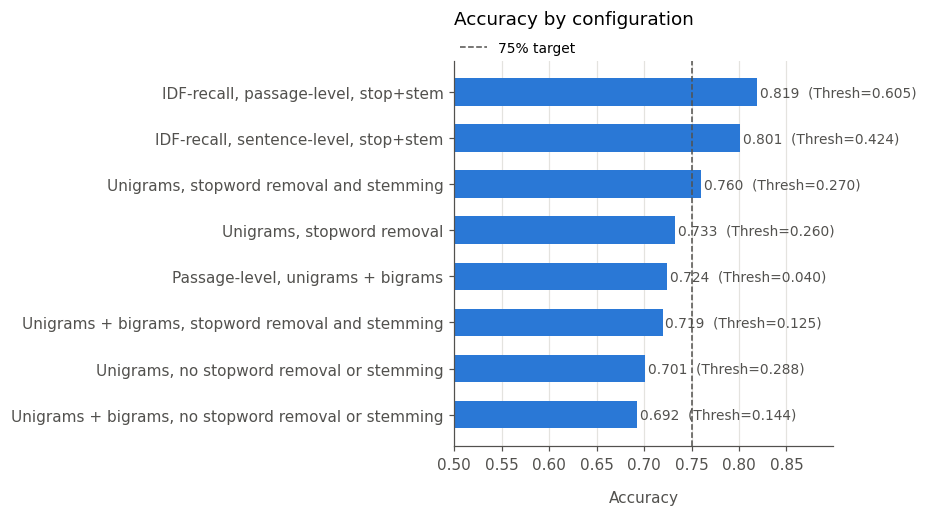

In [56]:
# Ablation accuracy per configuration (best threshold each)
ordered = sorted(ablation_results, key=lambda r: r["metrics"]["accuracy"])
names = [r["name"] for r in ordered]
accs = [r["metrics"]["accuracy"] for r in ordered]

# Prepare a horizontal bar chart to visualize the accuracy of each configuration.
fig, ax = plt.subplots(figsize=(8, 0.45 * len(ordered) + 1.2))
bars = ax.barh(names, accs, color=BLUE, height=0.6)
ax.axvline(TARGET, color=INK, linestyle="--", linewidth=1, label="75% target")

# Annotate each bar with its accuracy and threshold for clarity.
for bar, acc, r in zip(bars, accs, ordered):
    ax.text(acc + 0.003, bar.get_y() + bar.get_height() / 2,
            f"{acc:.3f}  (Thresh={r['metrics']['threshold']:.3f})",
            va="center", fontsize=9, color=INK)

# Set the x-axis limits, labels, title, and grid for better readability.
ax.set_xlim(0.5, max(accs) + 0.08)
ax.set_xlabel("Accuracy", labelpad=12)
ax.set_title("Accuracy by configuration", loc="left", pad=24)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0),
          fontsize=9, borderaxespad=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "ablation_accuracy.png", bbox_inches="tight")
plt.show()